In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from datetime import datetime, date

In [2]:
ds = xr.load_dataset("../Part1_analysis/ERA5_features/grib_files/soil_moist_layer1.grib", engine="cfgrib")
var_daily1 = ds.swvl1.groupby(ds.swvl1.time.dt.date).mean()

Ignoring index file '../Part1_analysis/ERA5_features/grib_files/soil_moist_layer1.grib.5b7b6.idx' incompatible with GRIB file


In [3]:
ds = xr.load_dataset("../Part1_analysis/ERA5_features/grib_files/soil_moist_layer2.grib", engine="cfgrib")
var_daily2 = ds.swvl2.groupby(ds.swvl2.time.dt.date).mean()

Ignoring index file '../Part1_analysis/ERA5_features/grib_files/soil_moist_layer2.grib.5b7b6.idx' incompatible with GRIB file


In [4]:
var_daily = var_daily1 + var_daily2
var_daily = var_daily.reset_coords(['number', 'step'], drop=True)

In [5]:
dates = var_daily.date.data
datetimes = np.zeros_like(dates)
for i in range(len(dates)):
    datetimes[i] = datetime.combine(dates[i], datetime.min.time())

In [6]:
var_daily.coords["time"] = ("date", datetimes)
var_daily = var_daily.swap_dims({"date": "time"})
var_daily = var_daily.reset_coords('date', drop=True)

In [7]:
var_daily = var_daily.sel(time=slice("1960-07", "2010-06"))
var_daily = var_daily.assign_coords({'month_day': 31*var_daily['time.month'] + var_daily['time.day']})

In [8]:
var_7dMean = var_daily.rolling(time=7, min_periods=7, center=True).mean()
month = var_7dMean.time.dt.month
day = var_7dMean.time.dt.day
var_7dMean = var_7dMean.sel(time=~( ((month==10)&(day<4)) | ((month==2)&(day>25)) ))

In [9]:
var_7dMean_anom = var_7dMean.groupby('month_day') - var_7dMean.groupby('month_day').mean()

In [10]:
fit_params = var_7dMean_anom.polyfit('time', 1).polyfit_coefficients
var_7dMean_anom_detr = var_7dMean_anom - xr.polyval(var_7dMean_anom.time, fit_params)

In [11]:
month = var_7dMean_anom_detr.time.dt.month
day = var_7dMean_anom_detr.time.dt.day
var_7dMean_anom_detr_week1 = var_7dMean_anom_detr.sel(time = ((month == 11) & (day >= 27)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 18)))
var_7dMean_anom_detr_week2 = var_7dMean_anom_detr.sel(time = ((month == 11) & (day >= 20)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 11)))
var_7dMean_anom_detr_week3 = var_7dMean_anom_detr.sel(time = ((month == 11) & (day >= 13)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 4)))
var_7dMean_anom_detr_week4 = var_7dMean_anom_detr.sel(time = ((month == 11) & (day >= 6)) | (month == 12) | ((month == 1) & (day <= 28)))

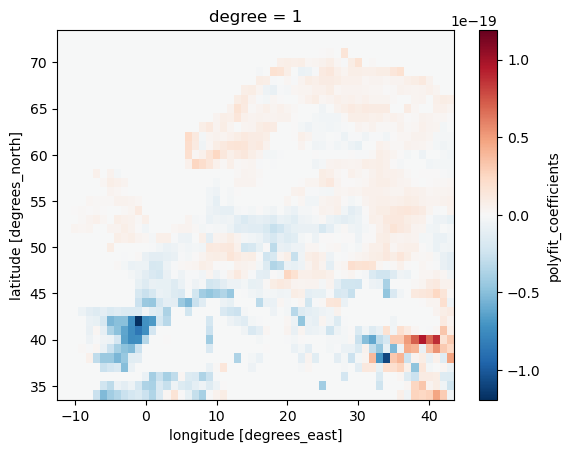

In [12]:
fit_params[0].plot()

In [13]:
ds_oro = xr.load_dataset("../Part1_analysis/ERA5_features/grib_files/orography_1deg_res.grib", engine="cfgrib")
ds_oro = ds_oro.reset_coords(['number', 'time', 'step', 'surface', 'valid_time'], drop=True)

Ignoring index file '../Part1_analysis/ERA5_features/grib_files/orography_1deg_res.grib.5b7b6.idx' incompatible with GRIB file


In [14]:
df_target = pd.read_csv('../Part1_analysis/target_temp_NE_quadr_moanom.csv')

In [15]:
target = var_7dMean_anom_detr_week3.mean(dim=['longitude', 'latitude'])
target[:] = df_target[840:5040]['t2m']

In [16]:
spearman_corr_temp = var_7dMean_anom_detr_week3.mean('time')
pvalue_temp = var_7dMean_anom_detr_week3.mean('time')
for i in range(len(var_7dMean_anom_detr_week3.longitude)):
    for j in range(len(var_7dMean_anom_detr_week3.latitude)):
        spearman = spearmanr( var_7dMean_anom_detr_week3[:,j,i], target )
        spearman_corr_temp[j,i] = spearman.statistic
        pvalue_temp[j,i] = spearman.pvalue

In [17]:
df_target2 = pd.read_csv('../Part1_analysis/target_precip_NE_lin_moanom.csv')

In [18]:
target2 = var_7dMean_anom_detr_week3.mean(dim=['longitude', 'latitude'])
target2[:] = df_target2[840:5040]['tp']

In [19]:
spearman_corr_precip = var_7dMean_anom_detr_week3.mean('time')
pvalue_precip = var_7dMean_anom_detr_week3.mean('time')
for i in range(len(var_7dMean_anom_detr_week3.longitude)):
    for j in range(len(var_7dMean_anom_detr_week3.latitude)):
        spearman = spearmanr( var_7dMean_anom_detr_week3[:,j,i], target2 )
        spearman_corr_precip[j,i] = spearman.statistic
        pvalue_precip[j,i] = spearman.pvalue

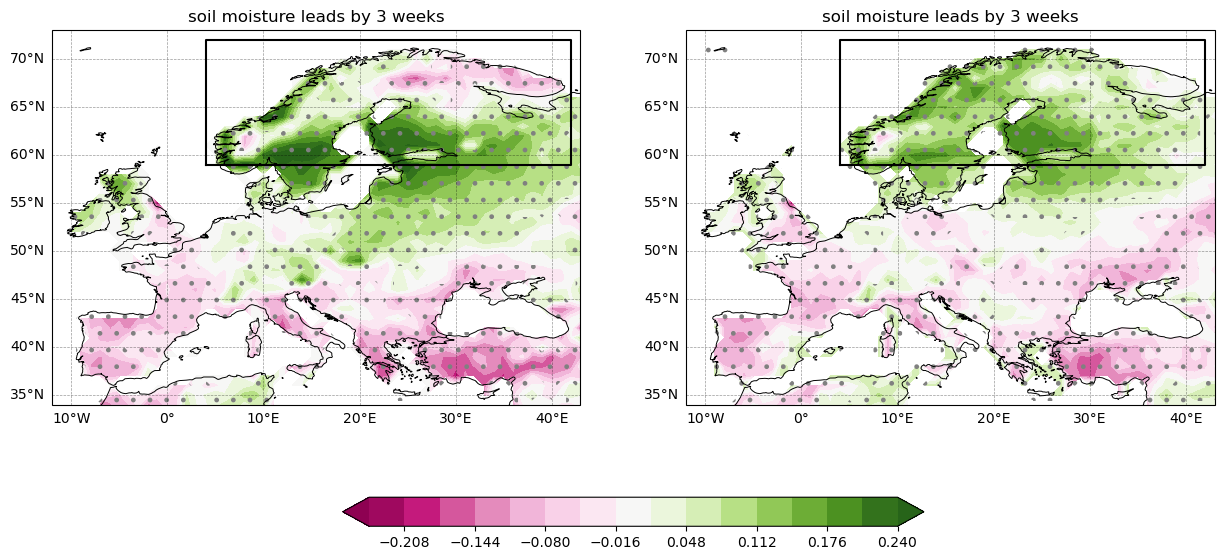

In [20]:
maps = [spearman_corr_temp, spearman_corr_precip]
pvalues = [pvalue_temp, pvalue_precip]

fig = plt.figure(figsize=(15,8))
plt.rcParams["hatch.color"] = "grey"

for i in range(2):
    ax = fig.add_subplot(1,2,i+1, projection=ccrs.PlateCarree())
    ax.coastlines(resolution='50m', linewidth=0.7)
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.4, color='k', linestyle='--')
    gl.right_labels = False
    gl.top_labels = False
    contf = ax.contourf(maps[i].longitude, maps[i].latitude, maps[i].where(ds_oro.lsm > 0), levels=np.linspace(-0.24,0.24,16), cmap='PiYG',extend='both')
    hatches = ax.contourf(pvalues[i].longitude, pvalues[i].latitude, pvalues[i].where(ds_oro.lsm > 0)<0.05 ,hatches=[None, '.'], alpha=0)
    ax.set_title('soil moisture leads by 3 weeks')
    ax.plot([4,42,42,4,4], [59,59,72,72,59], 'k')

cbar = fig.colorbar(contf, ax=fig.axes, location='bottom', shrink=0.5)

In [21]:
df_target3_0 = pd.read_csv('../Part1_analysis/NAO_week3.csv')
df_target3_1 = pd.read_csv('../Part1_analysis/NAO_week4.csv')
df_target3_2 = pd.read_csv('../Part1_analysis/NAO_week5.csv')
df_target3_3 = pd.read_csv('../Part1_analysis/NAO_week6.csv')

In [22]:
target3 = var_7dMean_anom_detr_week3.mean(dim=['longitude', 'latitude'])
target3[:] = (df_target3_0[840:5040]['nao_index']+df_target3_1[840:5040]['nao_index']+df_target3_2[840:5040]['nao_index']+df_target3_3[840:5040]['nao_index'])/4

In [23]:
spearman_corr_nao = var_7dMean_anom_detr_week3.mean('time')
pvalue_nao = var_7dMean_anom_detr_week3.mean('time')
for i in range(len(var_7dMean_anom_detr_week3.longitude)):
    for j in range(len(var_7dMean_anom_detr_week3.latitude)):
        spearman = spearmanr( var_7dMean_anom_detr_week3[:,j,i], target3 )
        spearman_corr_nao[j,i] = spearman.statistic
        pvalue_nao[j,i] = spearman.pvalue

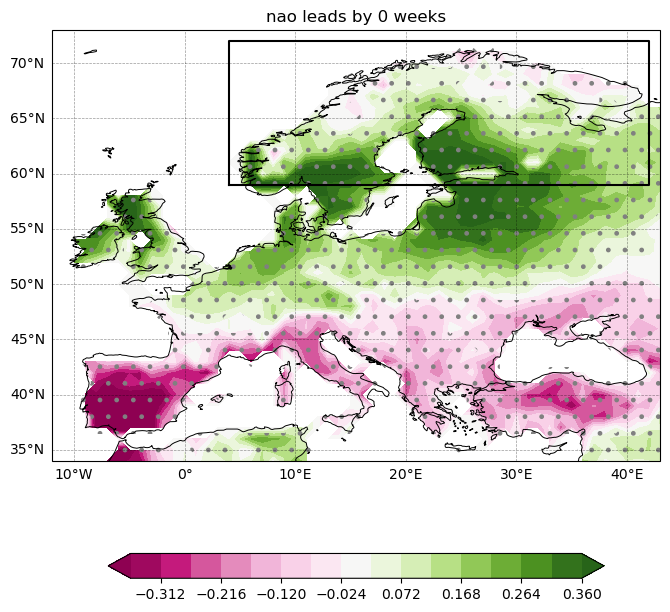

In [24]:
maps = [spearman_corr_nao]
pvalues = [pvalue_nao]

fig = plt.figure(figsize=(8,8))
plt.rcParams["hatch.color"] = "grey"

for i in range(1):
    ax = fig.add_subplot(1,1,i+1, projection=ccrs.PlateCarree())
    ax.coastlines(resolution='50m', linewidth=0.7)
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.4, color='k', linestyle='--')
    gl.right_labels = False
    gl.top_labels = False
    contf = ax.contourf(maps[i].longitude, maps[i].latitude, maps[i].where(ds_oro.lsm > 0), levels=np.linspace(-0.36,0.36,16), cmap='PiYG',extend='both')
    hatches = ax.contourf(pvalues[i].longitude, pvalues[i].latitude, pvalues[i].where(ds_oro.lsm > 0)<0.05 ,hatches=[None, '.'], alpha=0)
    ax.set_title('nao leads by 0 weeks')
    ax.plot([4,42,42,4,4], [59,59,72,72,59], 'k')

cbar = fig.colorbar(contf, ax=fig.axes, location='bottom', shrink=0.8)

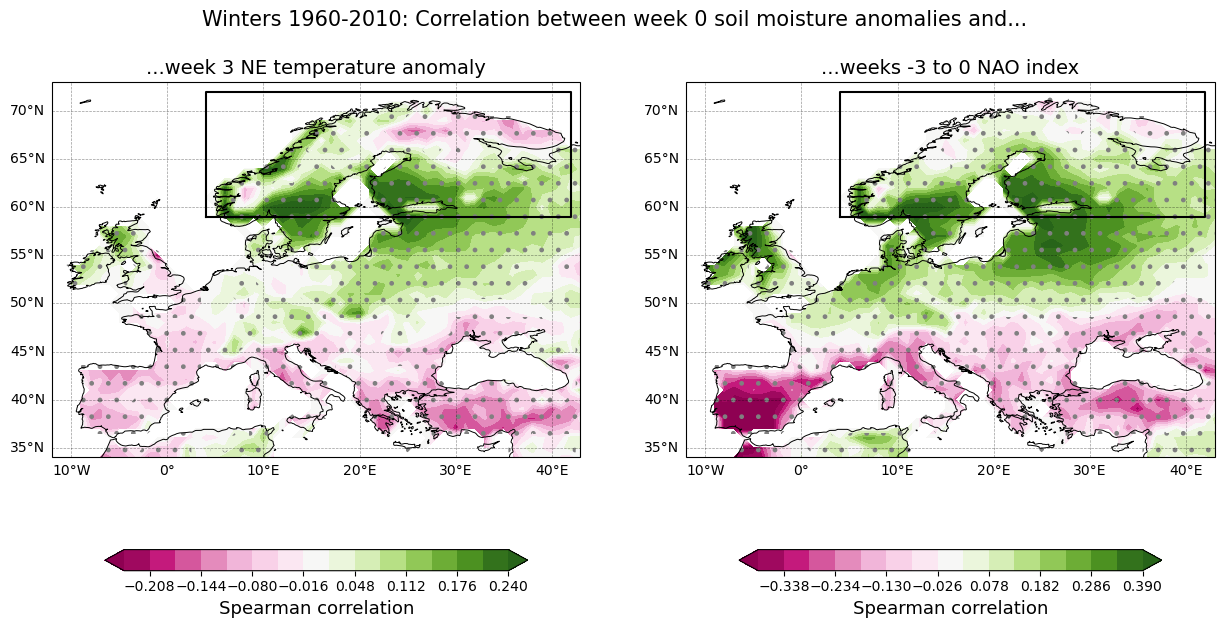

In [30]:
maps = [spearman_corr_temp, spearman_corr_nao]
pvalues = [pvalue_temp, pvalue_nao]
bvals = [0.24, 0.39]
titles = ['...week 3 NE temperature anomaly', '...weeks -3 to 0 NAO index']

fig = plt.figure(figsize=(15,8))
fig.suptitle('Winters 1960-2010: Correlation between week 0 soil moisture anomalies and...',y=0.9,fontsize=15)
plt.rcParams["hatch.color"] = "grey"

for i in range(2):
    ax = fig.add_subplot(1,2,i+1, projection=ccrs.PlateCarree())
    ax.coastlines(resolution='50m', linewidth=0.7)
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.4, color='k', linestyle='--')
    gl.right_labels = False
    gl.top_labels = False
    contf = ax.contourf(maps[i].longitude, maps[i].latitude, maps[i].where(ds_oro.lsm > 0), levels=np.linspace(-bvals[i],bvals[i],16), 
                        cmap='PiYG',extend='both')
    hatches = ax.contourf(pvalues[i].longitude, pvalues[i].latitude, pvalues[i].where(ds_oro.lsm > 0)<0.05 ,hatches=[None, '.'], alpha=0)
    ax.set_title(titles[i], fontsize=14)
    ax.plot([4,42,42,4,4], [59,59,72,72,59], 'k')
    cbar = fig.colorbar(contf, ax=ax, location='bottom', shrink=0.8)
    cbar.set_label('Spearman correlation',fontsize=13)
    cbar.ax.tick_params(labelsize=10)

plt.savefig('sm_correlation_maps_temp.pdf', bbox_inches='tight')

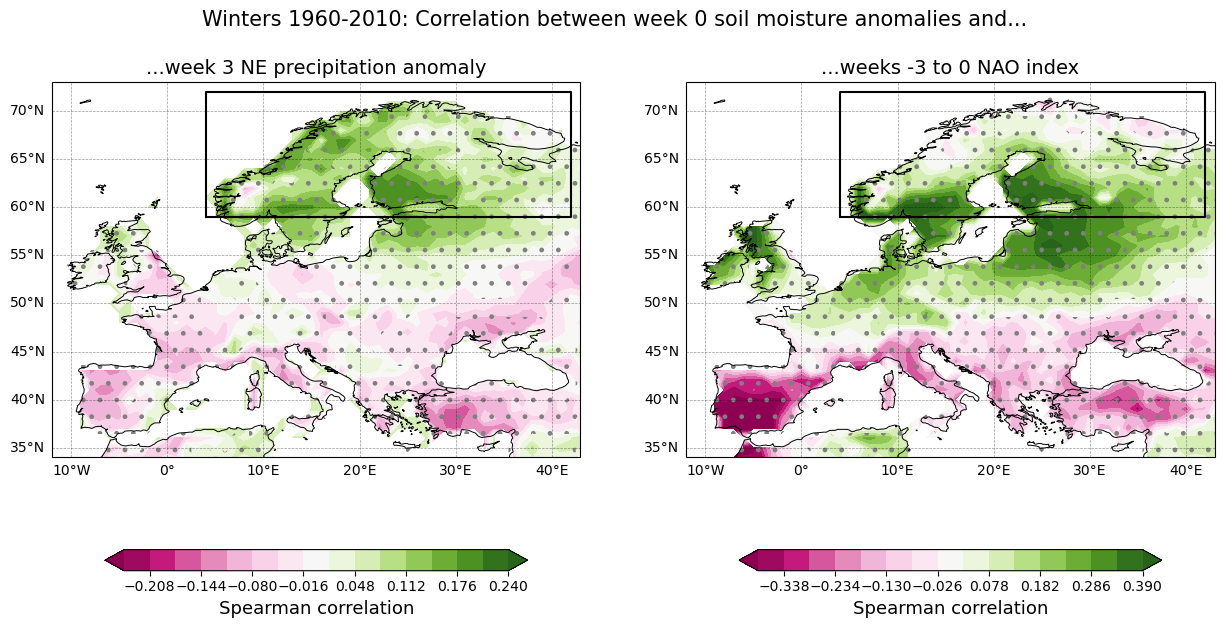

In [31]:
maps = [spearman_corr_precip, spearman_corr_nao]
pvalues = [pvalue_temp, pvalue_nao]
bvals = [0.24, 0.39]
titles = ['...week 3 NE precipitation anomaly', '...weeks -3 to 0 NAO index']

fig = plt.figure(figsize=(15,8))
fig.suptitle('Winters 1960-2010: Correlation between week 0 soil moisture anomalies and...',y=0.9,fontsize=15)
plt.rcParams["hatch.color"] = "grey"

for i in range(2):
    ax = fig.add_subplot(1,2,i+1, projection=ccrs.PlateCarree())
    ax.coastlines(resolution='50m', linewidth=0.7)
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.4, color='k', linestyle='--')
    gl.right_labels = False
    gl.top_labels = False
    contf = ax.contourf(maps[i].longitude, maps[i].latitude, maps[i].where(ds_oro.lsm > 0), levels=np.linspace(-bvals[i],bvals[i],16), 
                        cmap='PiYG',extend='both')
    hatches = ax.contourf(pvalues[i].longitude, pvalues[i].latitude, pvalues[i].where(ds_oro.lsm > 0)<0.05 ,hatches=[None, '.'], alpha=0)
    ax.set_title(titles[i], fontsize=14)
    ax.plot([4,42,42,4,4], [59,59,72,72,59], 'k')
    cbar = fig.colorbar(contf, ax=ax, location='bottom', shrink=0.8)
    cbar.set_label('Spearman correlation',fontsize=13)
    cbar.ax.tick_params(labelsize=10)

plt.savefig('sm_correlation_maps_precip.pdf', bbox_inches='tight')